In [8]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [9]:
!kaggle datasets download -d puneet6060/intel-image-classification

100% 345M/346M [00:05<00:00, 37.5MB/s]
100% 346M/346M [00:05<00:00, 69.9MB/s]


In [10]:
import zipfile
zip_ref = zipfile.ZipFile('/content/intel-image-classification.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [11]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout

In [72]:
import os

dataset_path = "/content/seg_train"

categories = os.listdir(dataset_path)

print(f"Number of categories: {len(categories)}")
print("Categories:", categories)

Number of categories: 1
Categories: ['seg_train']


In [101]:
train_path = "/content/seg_train/seg_train"
test_path = "/content/seg_test/seg_test"
image_size = (150,150)
batch_size = 32

In [102]:

train_datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest')

train_generator = train_datagen.flow_from_directory(train_path,
                                                    target_size=image_size,
                                                    batch_size=batch_size,
                                                    class_mode='categorical',
                                                    shuffle=True)

Found 14034 images belonging to 6 classes.


In [103]:
test_datagen = ImageDataGenerator(rescale=1./255)


validation_generator = test_datagen.flow_from_directory(
        test_path,
        target_size=image_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True)

Found 3000 images belonging to 6 classes.


In [104]:
labels = {value: key for key, value in train_generator.class_indices.items()}

print("Label in in train and validation datasets\n")

for key, value in labels.items():
    print(f'{key} : {value}')

Label in in train and validation datasets

0 : buildings
1 : forest
2 : glacier
3 : mountain
4 : sea
5 : street


In [105]:
model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(150,150,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2))
model.add(Dropout(0.2))

model.add(Conv2D(64,kernel_size=(3,3),activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2))
model.add(Dropout(0.2))

model.add(Conv2D(128,kernel_size=(3,3),padding='same',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='same'))
model.add(Dropout(0.2))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(Dense(6,activation='softmax'))


"model.add(Dropout(0.1))\nmodel.add(Dense(1,activation='sigmoid'))"

In [106]:
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_7 (Conv2D)           (None, 148, 148, 32)      896       
                                                                 
 batch_normalization_7 (Bat  (None, 148, 148, 32)      128       
 chNormalization)                                                
                                                                 
 max_pooling2d_7 (MaxPoolin  (None, 74, 74, 32)        0         
 g2D)                                                            
                                                                 
 dropout_2 (Dropout)         (None, 74, 74, 32)        0         
                                                                 
 conv2d_8 (Conv2D)           (None, 72, 72, 64)        18496     
                                                                 
 batch_normalization_8 (Bat  (None, 72, 72, 64)       

In [109]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [110]:
history = model.fit(train_generator,epochs=30,validation_data=validation_generator ,batch
                    _size = 64,verbose=1)

Epoch 1/30
439/439 [==============================] - 106s 230ms/step - loss: 0.3405 - accuracy: 0.6655 - val_loss: 0.3731 - val_accuracy: 0.5510
Epoch 2/30
439/439 [==============================] - 93s 212ms/step - loss: 0.2019 - accuracy: 0.7644 - val_loss: 0.7042 - val_accuracy: 0.3223
Epoch 3/30
439/439 [==============================] - 93s 211ms/step - loss: 0.1750 - accuracy: 0.7983 - val_loss: 0.2666 - val_accuracy: 0.6673
Epoch 4/30
439/439 [==============================] - 92s 210ms/step - loss: 0.1641 - accuracy: 0.8140 - val_loss: 0.1556 - val_accuracy: 0.8317
Epoch 5/30
439/439 [==============================] - 92s 209ms/step - loss: 0.1468 - accuracy: 0.8319 - val_loss: 0.2680 - val_accuracy: 0.7193
Epoch 6/30
439/439 [==============================] - 94s 214ms/step - loss: 0.1330 - accuracy: 0.8536 - val_loss: 0.2146 - val_accuracy: 0.7697
Epoch 7/30
439/439 [==============================] - 93s 213ms/step - loss: 0.1691 - accuracy: 0.8070 - val_loss: 0.4132 - val_a

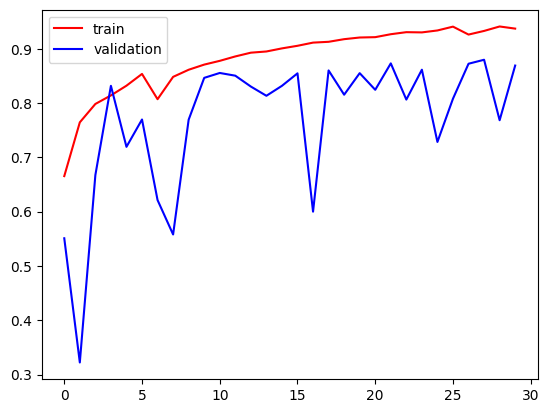

In [111]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

In [112]:
model.evaluate(validation_generator)

94/94 [==============================] - 5s 46ms/step - loss: 0.1322 - accuracy: 0.8690


[0.13224658370018005, 0.8690000176429749]

In [113]:
test_predictions = model.predict(validation_generator)
test_predictions_classes = np.where(test_predictions > 0.5, 1, 0)

94/94 [==============================] - 3s 35ms/step


In [127]:
print(test_predictions)

[[1.5928521e-08 1.2885103e-07 8.6524970e-08 2.0929922e-06 1.6207761e-06
  9.9999607e-01]
 [1.0103331e-06 1.7825125e-05 6.1687850e-04 9.9931419e-01 5.0130635e-05
  1.8290031e-09]
 [3.2668996e-11 2.4231049e-05 3.3286778e-04 9.9964106e-01 1.9429062e-06
  2.8303822e-09]
 ...
 [1.3335995e-06 6.0301861e-09 9.9044341e-01 9.4079599e-03 6.0980897e-06
  1.4126582e-04]
 [3.6860612e-10 1.0000000e+00 5.1087198e-08 1.4895057e-09 1.9485759e-08
  2.9677283e-12]
 [5.0030444e-03 6.9721436e-06 9.9464118e-01 3.0411963e-04 3.3157183e-05
  1.1594364e-05]]


In [128]:
print(test_predictions_classes)

[[0 0 0 0 0 1]
 [0 0 0 1 0 0]
 [0 0 0 1 0 0]
 ...
 [0 0 1 0 0 0]
 [0 1 0 0 0 0]
 [0 0 1 0 0 0]]


In [117]:
import cv2


In [65]:
test_img.shape

(220, 440, 3)

In [66]:
test_img = cv2.resize(test_img,(64,64))

In [67]:
input_image = test_img.reshape((1,64,64,3))

In [68]:
model.predict(input_image)

1/1 [==============================] - 0s 77ms/step


array([[0., 0., 1., 0., 0., 0.]], dtype=float32)

In [120]:
test_img = cv2.imread('/content/seg_test/seg_test/buildings/20061.jpg')

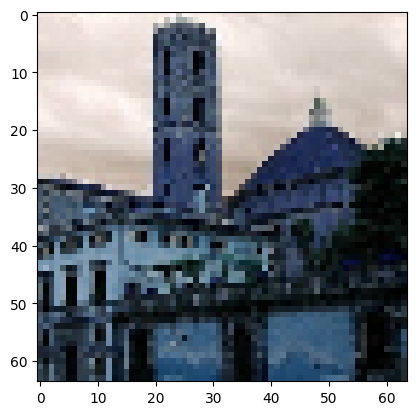

In [124]:
plt.imshow(test_img)
test_img = cv2.resize(test_img,(150,150))

In [125]:
input_image = test_img.reshape((1,150,150,3))

In [126]:
model.predict(input_image)

1/1 [==============================] - 0s 309ms/step


array([[0., 0., 1., 0., 0., 0.]], dtype=float32)

In [93]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import tensorflow as tf
from keras.preprocessing.image import ImageDataGenerator
from keras.preprocessing import image
tf.__version__

'2.15.0'

In [138]:
import os
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Define function to predict and get category label
def predict_and_get_label(model, image_path):
  # Load and pre-process image
  img = load_img(image_path, target_size=(150, 150))  # Adjust size if needed
  x = img_to_array(img) / 255.0  # Normalize pixel values
  x = np.expand_dims(x, axis=0)  # Add batch dimension

  # Make prediction
  prediction = model.predict(x)

  # Get the index of highest probability
  predicted_class_index = np.argmax(prediction)

  # Map index to category label
  category_labels = ["buildings", "forest", "glacier", "mountain", "sea", "street"]
  predicted_category = category_labels[predicted_class_index]

  # Return the predicted category
  return predicted_category



In [139]:
# Replace with your model and image path
model = model # Load your trained CNN model
image_path = "/content/building.jpeg"

# Predict and get label
predicted_category = predict_and_get_label(model, image_path)

# Print the prediction
print(f"Predicted category: {predicted_category}")

1/1 [==============================] - 0s 19ms/step
Predicted category: buildings


#pickling the model

In [133]:
#improt pickle
import pickle


In [134]:
# save your model in new model_saved file
pickle.dump(model, open("/content/model_saved","wb"))

In [136]:
# load the file once you want to do use it
model_loaded = pickle.load(open("/content/model_saved","rb"))

In [140]:
# Predict and get label
predicted_category = predict_and_get_label(model_loaded,"/content/seg_test/seg_test/forest/20089.jpg")

# Print the prediction
print(f"Predicted category: {predicted_category}")

1/1 [==============================] - 0s 113ms/step
Predicted category: forest
